# 05 - Keras (TensorFlow) Neural Network

A **multi-layer perceptron (MLP)**: fully connected (Dense) layers with ReLU activations, and one output layer with 3 neurons, one each for 1M, 5Y and 30Y. All three targets are predicted together by one network.

- **Loss:** mean squared error. **Optimizer:** Adam.
- **Dropout:** randomly switches off some neurons during training to reduce overfitting.
- **Early stopping:** stop when the validation loss hasn't improved for 20 epochs, and keep the best weights.
- Inputs and targets are standardised with the training data (`features.scale`).
- Neural nets give slightly different results for every random seed, so the final model is trained with **3 seeds** and we report the average.

In [1]:
import sys
import time
import os
sys.path.append("..")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # hide TensorFlow info messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")      # hide "retracing" warnings from predict() in loops
tf.config.experimental.enable_op_determinism()   # same result every time for the same seed

from src import config, features, evaluate, plots

plots.setup()
pd.set_option("display.precision", 4)
df = features.load_dataset()
print("Keras", keras.__version__, "with backend", keras.backend.backend())

Keras 3.15.1 with backend tensorflow


## 1. Model

In [2]:
def train_keras(X_train, y_train, X_val, y_val, units, dropout, lr, seed=config.SEED):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential()
    model.add(keras.Input(shape=(X_train.shape[1],)))
    for n in units:
        model.add(keras.layers.Dense(n, activation="relu"))
        model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(3))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mse")
    stop = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=300,
                        batch_size=64, callbacks=[stop], verbose=0)
    return model, history


configs = [{"units": units, "dropout": dropout, "lr": 1e-3}
           for units in [(32,), (64, 32), (128, 64)]
           for dropout in [0.0, 0.2]]
pd.DataFrame(configs)

,units,dropout,lr
0,"(32,)",0.0,0.001
1,"(32,)",0.2,0.001
2,"(64, 32)",0.0,0.001
3,"(64, 32)",0.2,0.001
4,"(128, 64)",0.0,0.001
5,"(128, 64)",0.2,0.001


## 2. Tuning on the validation set (seed 42)

In [3]:
best_config, tuning_rows = {}, []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, x_scaler, unscale_y = features.scale(data)
    (X_train, y_train), (X_val, y_val) = scaled["train"], scaled["val"]
    for cfg in configs:
        model, history = train_keras(X_train, y_train, X_val, y_val, **cfg)
        val_pred = evaluate.to_level(unscale_y(model.predict(X_val, verbose=0)), data["val"]["today"], mode)
        val_rmse = evaluate.average_rmse(data["val"]["future"], val_pred)
        tuning_rows.append({"experiment": exp, **cfg, "epochs": len(history.history["loss"]),
                            "val RMSE (avg)": val_rmse})
    rows = [r for r in tuning_rows if r["experiment"] == exp]
    best = min(rows, key=lambda r: r["val RMSE (avg)"])
    best_config[exp] = {k: best[k] for k in ["units", "dropout", "lr"]}
tuning = pd.DataFrame(tuning_rows)
tuning

,experiment,units,dropout,lr,epochs,val RMSE (avg)
0,A,"(32,)",0.0,0.001,52,0.2541
1,A,"(32,)",0.2,0.001,54,0.2625
2,A,"(64, 32)",0.0,0.001,81,0.3239
3,A,"(64, 32)",0.2,0.001,49,0.3491
4,A,"(128, 64)",0.0,0.001,40,0.3015
5,A,"(128, 64)",0.2,0.001,46,0.2891
6,B,"(32,)",0.0,0.001,36,0.1626
7,B,"(32,)",0.2,0.001,30,0.1712
8,B,"(64, 32)",0.0,0.001,24,0.1666
9,B,"(64, 32)",0.2,0.001,23,0.1635


In [4]:
pd.DataFrame(best_config).T

,units,dropout,lr
A,"(32,)",0.0,0.001
B,"(32,)",0.0,0.001
C,"(64, 32)",0.0,0.001


## 3. Final models: 3 seeds per experiment

In [5]:
all_metrics, times = [], []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, x_scaler, unscale_y = features.scale(data)
    (X_train, y_train), (X_val, y_val), (X_test, y_test) = scaled["train"], scaled["val"], scaled["test"]
    for seed in config.SEEDS:
        start = time.time()
        model, history = train_keras(X_train, y_train, X_val, y_val, seed=seed, **best_config[exp])
        if exp == "C":
            times.append(time.time() - start)
        pred_level = evaluate.to_level(unscale_y(model.predict(X_test, verbose=0)), data["test"]["today"], mode)
        evaluate.save_predictions("Keras", exp, seed, data["test"], pred_level)
        m = evaluate.evaluate(data["test"]["future"], pred_level, data["test"]["today"])
        all_metrics.append(m.assign(experiment=exp, seed=seed).reset_index())
        if exp == "C" and seed == config.SEED:
            model_c, history_c, scaler_c, unscale_c = model, history, x_scaler, unscale_y

metrics = pd.concat(all_metrics)
summary = metrics.groupby(["experiment", "target"])[["RMSE", "MAE", "R2", "R2_change", "skill_vs_naive", "direction_acc"]]
order = ["1M", "5Y", "30Y"]
summary.mean().reindex(order, level=1).round(4)

RMSE     MAE      R2  R2_change  skill_vs_naive  \
experiment target                                                      
A          1M      0.4120  0.3724  0.6376    -7.2360         -1.8056   
           5Y      0.2612  0.2108  0.3927    -2.8104         -0.8943   
           30Y     0.6059  0.5727 -1.4956   -36.1113         -4.4551   
B          1M      0.1578  0.0824  0.9491    -0.1568         -0.0749   
           5Y      0.1554  0.1218  0.7961    -0.2794         -0.1267   
           30Y     0.1366  0.1096  0.8961    -0.5449         -0.2294   
C          1M      0.1576  0.0711  0.9491    -0.1578         -0.0736   
           5Y      0.1443  0.1113  0.8249    -0.0988         -0.0463   
           30Y     0.1249  0.0992  0.9128    -0.2963         -0.1241   

                   direction_acc  
experiment target                 
A          1M             0.5454  
           5Y             0.5185  
           30Y            0.4478  
B          1M             0.4985  
           5Y             0.4778  
           30Y            0.4770  
C          1M             0.5306  
           5Y             0.4859  
           30Y            0.4811

Spread between the 3 seeds (standard deviation of the test RMSE and skill):

In [6]:
summary.std()[["RMSE", "skill_vs_naive"]].reindex(order, level=1).round(4)

RMSE  skill_vs_naive
experiment target                        
A          1M      0.1085          0.7390
           5Y      0.0780          0.5653
           30Y     0.3619          3.2580
B          1M      0.0065          0.0445
           5Y      0.0142          0.1027
           30Y     0.0202          0.1815
C          1M      0.0129          0.0876
           5Y      0.0066          0.0479
           30Y     0.0206          0.1857

In [7]:
evaluate.save_run_info("Keras", {"train_seconds": float(np.mean(times)),
                                 "lines_of_code": evaluate.count_lines(train_keras),
                                 "hyperparameters": 7,
                                 "tuning_combinations": len(configs)})

**Observations**
- **Experiment A (level):** unlike trees, a neural network *can* output values outside the training range, but it doesn't learn the right relationship for yield levels it has never seen. RMSE is 26-61 bp (skill −0.9 to −4.5), and the results change a lot from seed to seed (standard deviation of skill up to 3.3).
- **B and C** are much better but **still worse than naive** for every target (skill −0.05 to −0.23). C is the best Keras setup for the 5Y (−0.046) and 30Y (−0.124).
- Direction accuracy is 48-53%, about a coin flip.
- **The seed matters:** in experiment C the skill varies by 0.05-0.19 between seeds, which is bigger than many of the differences between models. That's why results are averaged over 3 seeds.
- Validation chose the **smallest networks and no dropout**. Extra capacity only learns noise.

## 4. Training curve (experiment C, seed 42)

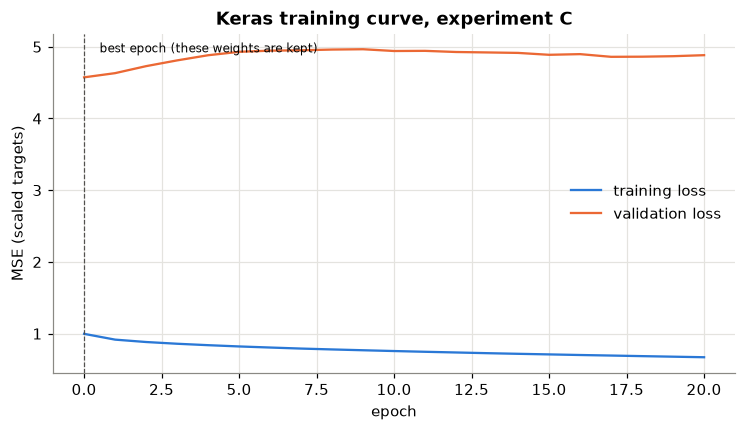

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_c.history["loss"], color=plots.BLUE, label="training loss")
ax.plot(history_c.history["val_loss"], color=plots.ORANGE, label="validation loss")
best_epoch = int(np.argmin(history_c.history["val_loss"]))
ax.axvline(best_epoch, color="#52514e", linestyle="--", linewidth=0.8)
ax.text(best_epoch + 0.5, ax.get_ylim()[1] * 0.95, "best epoch (these weights are kept)", fontsize=8)
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (scaled targets)")
ax.set_title("Keras training curve, experiment C")
ax.legend()
plots.save(fig, "05_keras_training_curve")
plt.show()

**Observations**
- The validation loss is lowest right **after the first epoch** and then goes *up*, while the training loss keeps going down. This is overfitting from the very start: whatever the network learns about 2010-2021 makes its predictions for 2022 worse.
- Early stopping therefore keeps the weights from after the first epoch, a nearly untrained network that predicts close to the average change. That's why Keras ends up close to (but slightly worse than) the naive forecast.
- The validation loss (about 4.6) is much higher than the training loss (about 1) because the targets were scaled with training statistics, and weekly moves in 2022 were roughly twice as large as in 2010-2021.

## 5. Permutation feature importance (experiment C)

A neural network has no built-in feature importance. **Permutation importance** shuffles one feature at a time on the test set and measures how much the RMSE gets worse. If shuffling a feature hurts a lot, the model depends on it.

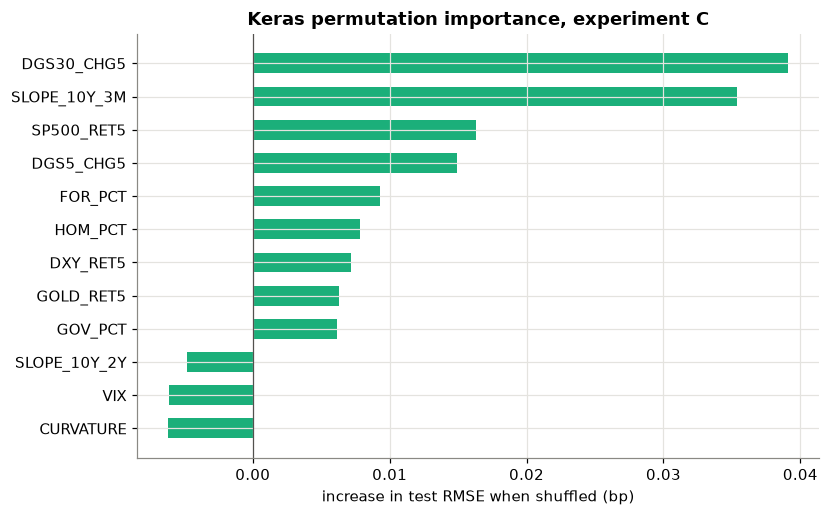

In [9]:
data_c, _ = features.get_experiment(df, "C")

def predict_level(X):
    pred = model_c.predict(scaler_c.transform(X).astype("float32"), verbose=0)
    return evaluate.to_level(unscale_c(pred), data_c["test"]["today"], "change")

importance = evaluate.permutation_importance(predict_level, data_c["test"]["X"], data_c["test"]["future"])
evaluate.save_importance("Keras", importance, "permutation_rmse_increase")

fig, ax = plt.subplots(figsize=(8, 5))
top = importance.head(12).iloc[::-1] * 100
ax.barh(top.index, top.values, color=plots.MODEL_COLORS["Keras"], height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("increase in test RMSE when shuffled (bp)")
ax.set_title("Keras permutation importance, experiment C")
plots.save(fig, "05_keras_importance")
plt.show()

**Observations**
- The importances are **tiny**: shuffling the most important feature (the 30Y's change over the past week) raises the test RMSE by only 0.04 bp. The predictions hardly depend on the inputs at all, which fits a network that stopped after one epoch.
- Negative values (10Y-2Y slope, VIX, curvature) mean shuffling made the model slightly *better*, so those inputs only add noise.
- The top features (30Y momentum, 10Y-3M slope) are the same ones linear regression and XGBoost use.